# Red neuronal funcional: ejecución y resultados
Las clases y funciones están en `funciones/Entrenamiento_red.py`; este notebook corre las comprobaciones, el entrenamiento y muestra los resultados.

In [1]:
import sys
sys.path.append('funciones')
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display
from Entrenamiento_red import *

## Comprobaciones de la cabeza MLP
Dimensiones, gradientes y semillas reproducibles para cada q y M, sin entrenamiento.

In [2]:
datos, W, R, cov_norm, opciones_q, opciones_m = main_cabeza_mlp()

q=6, M=4, ocultas=8: cabeza MLP=108 parámetros; 3 semillas correctas
q=6, M=5, ocultas=8: cabeza MLP=117 parámetros; 3 semillas correctas
q=6, M=6, ocultas=8: cabeza MLP=126 parámetros; 3 semillas correctas
q=7, M=4, ocultas=8: cabeza MLP=116 parámetros; 3 semillas correctas
q=7, M=5, ocultas=8: cabeza MLP=125 parámetros; 3 semillas correctas
q=7, M=6, ocultas=8: cabeza MLP=134 parámetros; 3 semillas correctas
q=8, M=4, ocultas=8: cabeza MLP=124 parámetros; 3 semillas correctas
q=8, M=5, ocultas=8: cabeza MLP=133 parámetros; 3 semillas correctas
q=8, M=6, ocultas=8: cabeza MLP=142 parámetros; 3 semillas correctas
Comprobaciones finalizadas. No se entrenó ni se generaron archivos.


## KAN: resolución de la malla

In [3]:
# Resolución de la malla para el seno de la función sintética
torch.set_num_threads(1)
x_malla = torch.linspace(-1, 1, 1001, dtype=torch.float64)
x_intermedia = (x_malla[:-1] + x_malla[1:]) / 2
resolucion = []
for intervalos in (4, 8, 12, 16):
    capa = CapaKAN(1, 1, intervalos)
    coeficientes = torch.linalg.lstsq(capa.bases(x_malla), torch.sin(2 * torch.pi * x_malla)).solution
    error = capa.bases(x_intermedia) @ coeficientes - torch.sin(2 * torch.pi * x_intermedia)
    resolucion.append({'intervalos': intervalos, 'RMSE_aproximacion': error.square().mean().sqrt().item()})
tabla_resolucion = pd.DataFrame(resolucion)
print(tabla_resolucion.to_string(index=False))
# Doce intervalos reducen el error de aproximación del seno a cerca de 0,00115

 intervalos  RMSE_aproximacion
          4           0.242062
          8           0.008393
         12           0.001151
         16           0.000312


## KAN: comprobación con una función sintética
La KAN debe aproximar la función sintética con RMSE ≤ 0,01 antes de usar datos reales.

In [4]:
# Comprobación sintética con ajuste, validación y verificación independientes
generador = torch.Generator().manual_seed(2026)
x_sintetica = 4 * torch.rand(2200, 8, generator=generador, dtype=torch.float64) - 2
funcion = torch.sin(torch.pi * x_sintetica[:, 0]) + x_sintetica[:, 1].square()
escalas_salida = torch.tensor([[0.5, 0.75, 1.0, 1.25]], dtype=torch.float64)
y_sintetica = funcion[:, None] * escalas_salida
x_ajuste, x_validacion, x_verificacion = x_sintetica[:1400], x_sintetica[1400:1800], x_sintetica[1800:]
y_ajuste, y_validacion, y_verificacion = y_sintetica[:1400], y_sintetica[1400:1800], y_sintetica[1800:]
resultados_sinteticos = []
for semilla in SEMILLAS:
    establecer_semilla(semilla)
    cabeza = CabezaKAN(neuronas=6, m_fpca=4)
    cabeza.calibrar(x_ajuste)
    optimizador = torch.optim.AdamW(cabeza.parameters(), lr=0.01, weight_decay=0)
    mejor_validacion = float('inf')
    sin_mejora = 0
    for epoca in range(1, 4001):
        cabeza.train()
        optimizador.zero_grad(set_to_none=True)
        perdida = (cabeza(x_ajuste) - y_ajuste).square().mean()
        perdida.backward()
        optimizador.step()
        cabeza.eval()
        with torch.no_grad():
            perdida_validacion = (cabeza(x_validacion) - y_validacion).square().mean().item()
        if perdida_validacion < mejor_validacion - 1e-10:
            mejor_validacion = perdida_validacion
            mejor_estado = {nombre: valor.detach().clone() for nombre, valor in cabeza.state_dict().items()}
            mejor_epoca = epoca
            sin_mejora = 0
        else:
            sin_mejora += 1
        if sin_mejora >= 300:
            break
    cabeza.load_state_dict(mejor_estado)
    with torch.no_grad():
        error_verificacion = cabeza(x_verificacion) - y_verificacion
        rmse_salida = error_verificacion.square().mean(dim=0).sqrt()
        rmse = error_verificacion.square().mean().sqrt().item()
    resultados_sinteticos.append({
        'semilla': semilla, 'mejor_epoca': mejor_epoca,
        'RMSE_validacion': np.sqrt(mejor_validacion), 'RMSE_verificacion': rmse,
        'RMSE_max_salida': rmse_salida.max().item(),
    })
    print(f'KAN sintética, semilla {semilla:04d}, RMSE de verificación = {rmse:.6f}')
    if semilla == SEMILLAS[0]:
        cabeza_sintetica = cabeza
tabla_sintetica = pd.DataFrame(resultados_sinteticos)
print(tabla_sintetica.to_string(index=False))
print(tabla_sintetica[['RMSE_verificacion', 'RMSE_max_salida']].agg(['mean', 'std']).to_string())
assert np.isfinite(tabla_sintetica['RMSE_max_salida']).all()
assert tabla_sintetica['RMSE_max_salida'].le(0.01).all(), 'La KAN supera el RMSE sintético permitido.'
tabla_sintetica.to_csv('Tablas/06_KAN_sintetica.csv', index=False)
# Las tres semillas quedan por debajo de 0,01 en cada una de las cuatro salidas sintéticas

KAN sintética, semilla 0001, RMSE de verificación = 0.002990


KAN sintética, semilla 0002, RMSE de verificación = 0.002271


KAN sintética, semilla 0003, RMSE de verificación = 0.002005
 semilla  mejor_epoca  RMSE_validacion  RMSE_verificacion  RMSE_max_salida
       1         1939         0.003022           0.002990         0.004122
       2         3968         0.002286           0.002271         0.003076
       3         2216         0.002106           0.002005         0.002796
      RMSE_verificacion  RMSE_max_salida
mean           0.002422         0.003331
std            0.000510         0.000699


## KAN: activaciones de la primera capa

In [5]:
# Activaciones de la primera capa en el rango del ajuste sintético
primera_capa = cabeza_sintetica.capas[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for entrada, ax in enumerate(axes):
    rejilla = torch.linspace(x_ajuste[:, entrada].min(), x_ajuste[:, entrada].max(), 200, dtype=torch.float64)
    for salida in range(OCULTAS_KAN):
        valores = primera_capa.arista(salida, entrada, rejilla)
        ax.plot(rejilla.numpy(), (valores - valores.mean()).numpy(), label=f'Arista hacia h{salida + 1}')
    ax.set_title(f'x{entrada + 1}')
    ax.legend(fontsize=8)
plt.suptitle('Primera capa KAN · función sintética · semilla 0001')
plt.tight_layout()
fig.savefig('Figuras/06_KAN_activaciones_sinteticas.png', dpi=150)
plt.close(fig)
# En la semilla 0001, las aristas hacia h2 recuperan el seno de x1 y la curvatura de x2

## KAN: ajuste simbólico

In [6]:
# Ajuste simbólico de la arista de x2 hacia la primera neurona oculta
rejilla = torch.linspace(x_ajuste[:, 1].min(), x_ajuste[:, 1].max(), 200, dtype=torch.float64)
coef_simbolicos, _, r2_simbolico = ajustar_simbolica(primera_capa, 0, 1, rejilla)
tabla_simbolica = pd.DataFrame([{
    'semilla': SEMILLAS[0], 'entrada': 1, 'salida': 0,
    'centro': primera_capa.centro[1].item(), 'escala': primera_capa.escala[1].item(),
    'a0': coef_simbolicos[0].item(), 'a1': coef_simbolicos[1].item(),
    'a2': coef_simbolicos[2].item(), 'a3': coef_simbolicos[3].item(),
    'R2_verificacion': r2_simbolico,
}])
print('Expresión de la arista sintética: a0 + a1*u + a2*u² + a3*u³, u = (x-centro)/escala')
print(tabla_simbolica.to_string(index=False))
# El polinomio aproxima la arista sintética con R² cercano a 0,908 en los puntos intercalados
tabla_simbolica.to_csv('Tablas/06_KAN_simbolica_sintetica.csv', index=False)

Expresión de la arista sintética: a0 + a1*u + a2*u² + a3*u³, u = (x-centro)/escala
 semilla  entrada  salida   centro   escala        a0        a1      a2       a3  R2_verificacion
       1        1       0 0.003881 1.993801 -0.558588 -0.032609 1.70964 0.096403          0.95258


## Integración del codificador y la KAN
Parámetros de KAN y MLP igualados (diferencia ≤ 10 %).

In [ ]:
# Integración del codificador y la KAN con entradas de entrenamiento
# 1. Verificar la partición temporal
anios = datos['YEAR'].to_numpy()
particiones = datos['particion'].to_numpy()
idx_entrenamiento = (particiones == 'entrenamiento')
idx_validacion = (particiones == 'validacion')
idx_prueba = (particiones == 'prueba')

# Verificar los intervalos establecidos
assert np.all((anios[idx_entrenamiento] >= 1981) & (anios[idx_entrenamiento] <= 1995))
assert np.all((anios[idx_validacion] >= 1996) & (anios[idx_validacion] <= 2000))
assert np.all((anios[idx_prueba] >= 2001) & (anios[idx_prueba] <= 2003))

# Comprobar que no existan particiones desconocidas
assert np.all(idx_entrenamiento | idx_validacion | idx_prueba)

# Resumen de particiones
print("Distribución de los datos:")
print(f"Entrenamiento (1981-1995): {idx_entrenamiento.sum()} curvas")
print(f"Validación (1996-2000): {idx_validacion.sum()} curvas")
print(f"Prueba (2001-2003): {idx_prueba.sum()} curvas")
print("\nPartición temporal verificada correctamente.")

# 2. Preparar entradas para la KAN
# Solo se utilizan datos de entrenamiento
c_entrenamiento = torch.as_tensor(datos['c'][idx_entrenamiento], dtype=torch.float64)
cov_entrenamiento = torch.as_tensor(cov_norm[idx_entrenamiento], dtype=torch.float64)

# 3. Comprobaciones del codificador y la KAN
comprobaciones = []
parametros_cabezas = []
for q in opciones_q:
    for m in opciones_m:
        for semilla in SEMILLAS:
            establecer_semilla(semilla)
            modelo = ModeloCodificadorCabezaKAN(W, R, q, m)
            with torch.no_grad():
                h_entrenamiento = modelo.codificador(c_entrenamiento, cov_entrenamiento)
                modelo.cabeza.calibrar(h_entrenamiento)
            c_lote = c_entrenamiento[:16]
            cov_lote = cov_entrenamiento[:16]
            coordenadas = modelo(c_lote, cov_lote)
            coordenadas.square().mean().backward()
            gradientes = all(
                p.grad is not None
                and torch.isfinite(p.grad).all().item()
                and p.grad.abs().sum().item() > 0
                for p in modelo.parameters()
            )
            establecer_semilla(semilla)
            replica = ModeloCodificadorCabezaKAN(W, R, q, m)
            with torch.no_grad():
                replica.cabeza.calibrar(replica.codificador(c_entrenamiento, cov_entrenamiento))
                error_replica = (coordenadas - replica(c_lote, cov_lote)).abs().max().item()
            comprobaciones.append({
                'q': q,
                'M': m,
                'semilla': semilla,
                'dimensiones_correctas': coordenadas.shape == (len(c_lote), m),
                'salida_finita': torch.isfinite(coordenadas).all().item(),
                'gradientes_finitos_no_nulos': gradientes,
                'error_replica': error_replica,
            })

        # 4. Comparación de parámetros KAN y MLP
        n_kan = contar_parametros(modelo.cabeza)
        ocultas_mlp = max(1, round((n_kan - m) / (q + m + 3)))
        n_mlp = contar_parametros(CabezaMLP(q, m, ocultas_mlp))
        parametros_cabezas.append({
            'q': q,
            'M': m,
            'ocultas_KAN': OCULTAS_KAN,
            'intervalos': INTERVALOS_KAN,
            'grado': 3,
            'parametros_KAN': n_kan,
            'ocultas_MLP': ocultas_mlp,
            'parametros_MLP': n_mlp,
            'diferencia_pct': 100 * abs(n_mlp - n_kan) / n_kan,
            'parametros_codificador': contar_parametros(modelo.codificador),
        })

# 5. Verificación de resultados
tabla_comprobaciones = pd.DataFrame(comprobaciones)
print(tabla_comprobaciones.to_string(index=False))
assert tabla_comprobaciones[['dimensiones_correctas', 'salida_finita', 'gradientes_finitos_no_nulos']].all().all()
assert tabla_comprobaciones['error_replica'].eq(0).all()
# El gradiente alcanza el codificador y las dos capas KAN
# con inicializaciones reproducibles
tabla_comprobaciones.to_csv('Tablas/06_KAN_comprobaciones.csv', index=False)

tabla_parametros = pd.DataFrame(parametros_cabezas)
print(tabla_parametros.to_string(index=False))
assert tabla_parametros['diferencia_pct'].le(10).all()
tabla_parametros.to_csv('Tablas/06_KAN_parametros.csv', index=False)
print('La KAN devuelve M coordenadas latentes.')

 q  M  semilla  dimensiones_correctas  salida_finita  gradientes_finitos_no_nulos  error_replica
 6  4        1                   True           True                         True            0.0
 6  4        2                   True           True                         True            0.0
 6  4        3                   True           True                         True            0.0
 6  5        1                   True           True                         True            0.0
 6  5        2                   True           True                         True            0.0
 6  5        3                   True           True                         True            0.0
 6  6        1                   True           True                         True            0.0
 6  6        2                   True           True                         True            0.0
 6  6        3                   True           True                         True            0.0
 7  4        1                

## Entrenamiento de la red funcional
Búsqueda de q y λ con validación, M = 5 para las tres cabezas, verificación de la equivalencia lineal y pesos guardados en `Resultados_Modelos1/`.

In [8]:
# Entrenamiento de la red funcional con la escala definida en ESCALA
if ESCALA is not None:
    resultados = main_entrenamiento(ESCALA)

lineal q=6 M=5 lambda=0.01 semilla=0001: validación=132.0662 (época 3000)


lineal q=6 M=5 lambda=0.01 semilla=0002: validación=116.2879 (época 848)


lineal q=6 M=5 lambda=0.01 semilla=0003: validación=145.1283 (época 3000)


lineal q=6 M=5 lambda=0.1 semilla=0001: validación=132.0622 (época 3000)


lineal q=6 M=5 lambda=0.1 semilla=0002: validación=115.4340 (época 847)


lineal q=6 M=5 lambda=0.1 semilla=0003: validación=145.1284 (época 3000)


... (180 outputs left out)

KAN q=8 M=5 lambda=10000.0 semilla=0001: validación=98.9651 (época 17)


KAN q=8 M=5 lambda=10000.0 semilla=0002: validación=109.2440 (época 35)


KAN q=8 M=5 lambda=10000.0 semilla=0003: validación=97.6152 (época 38)


        q  M  lambda        mean        std
cabeza                                     
KAN     8  5  100.00   99.691843  10.644825
MLP     8  5    0.01   98.219711  10.522763
lineal  8  5  100.00  122.412495   2.399474
 semilla  diferencia_max_integral  diferencia_max_coeficientes
       1             4.618528e-14                 1.421085e-14
       2             5.329071e-14                 1.598721e-14
       3             4.263256e-14                 1.421085e-14


## Resultados
### Parámetros de las cabezas

In [9]:
pd.read_csv('Tablas/08_red_parametros_cabezas.csv')

,q,M,parametros_lineal,parametros_KAN,ocultas_MLP,parametros_MLP,diferencia_pct
0,6,5,45,884,63,887,0.339367
1,7,5,50,952,63,950,0.210084
2,8,5,55,1020,63,1013,0.686275


### Varianza explicada de la FPCA

,M,varianza_explicada_acumulada
0,1,0.663174
1,2,0.788664
2,3,0.869657
3,4,0.921422
4,5,0.964234
5,6,1.000000


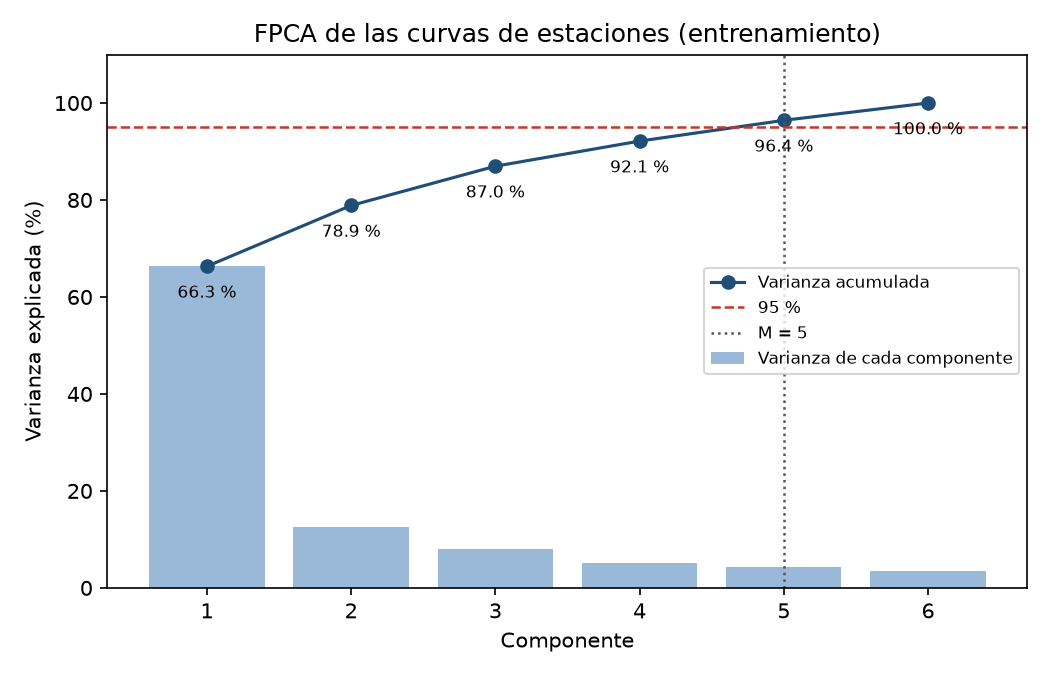

In [10]:
display(pd.read_csv('Tablas/08_red_fpca_varianza.csv'))
display(Image('Figuras/08_red_fpca_sedimentacion.png', width=650))

### Configuración elegida con validación
Pérdida L² funcional de validación en la escala √P (media y desviación de 3 semillas).

In [11]:
pd.read_csv('Tablas/08_red_configuracion_elegida.csv')

,cabeza,q,M,lambda,mean,std
0,KAN,8,5,100.00,99.691843,10.644825
1,MLP,8,5,0.01,98.219711,10.522763
2,lineal,8,5,100.00,122.412495,2.399474


In [12]:
pd.read_csv('Tablas/08_red_equivalencia_lineal.csv')

,semilla,diferencia_max_integral,diferencia_max_coeficientes
0,1,4.618528e-14,1.421085e-14
1,2,5.329071e-14,1.598721e-14
2,3,4.263256e-14,1.421085e-14


### Valores recortados en 0 al volver a mm (validación)

In [13]:
pd.read_csv('Tablas/08_red_valores_recortados.csv')

,cabeza,semilla,valores_recortados_pct
0,lineal,1,0.0
1,lineal,2,0.0
2,lineal,3,0.0
3,MLP,1,0.0
4,MLP,2,0.0
5,MLP,3,0.0
6,KAN,1,0.0
7,KAN,2,0.0
8,KAN,3,0.0


### Pérdida de validación por cabeza, q y λ (M = 5)

In [14]:
busqueda = pd.read_csv('Tablas/08_red_busqueda_hiperparametros.csv')
busqueda.groupby(['cabeza', 'q', 'lambda'])['perdida_validacion'].agg(['mean', 'std']).unstack('lambda').round(1)

mean                                                        \
lambda   0.01     0.10     1.00     10.00    100.00   1000.00  10000.00   
cabeza q                                                                  
KAN    6    106.8    106.8    106.8    106.8    106.1    106.7    103.1   
       7    131.9    131.2    131.3    131.6    131.4    126.5    125.4   
       8     99.8     99.8     99.8    100.9     99.7    102.3    101.9   
MLP    6    110.1    105.9    109.6     97.1    108.1     90.4     98.0   
       7    105.9    106.8    108.6    109.5    114.3    100.5    103.5   
       8     98.2    106.0    111.1    123.8    142.4    112.6    102.7   
lineal 6    131.2    130.9    131.1    130.8    130.2    131.3    132.9   
       7    128.0    128.0    128.3    127.9    125.6    127.2    131.6   
       8    122.9    123.0    123.4    122.7    122.4    123.9    129.7   

              std                                                        
lambda   0.01     0.10     1.00     10.00    100.00   1000.00  10000.00  
cabeza q                                                                 
KAN    6      8.0      8.0      8.0      8.0      8.0      5.9      2.2  
       7     18.7     18.1     18.1     18.6     16.5     15.2     21.7  
       8      9.3      9.3      9.2     11.1     10.6     11.0      6.4  
MLP    6     18.6     23.6     10.2      6.4     17.3      1.7     14.7  
       7      7.0     12.4     12.1     15.5     13.4     15.8      9.8  
       8     10.5     23.0     36.1     33.5     24.3     40.3     24.9  
lineal 6     14.4     14.9     14.4     14.9     14.5     13.1     11.1  
       7      6.4      6.4      5.9      6.3      6.5      5.1      6.3  
       8      2.5      2.5      2.0      2.7      2.4      6.1      8.3

### Pérdida y métricas durante el entrenamiento
Se vuelve a entrenar la configuración elegida de cada cabeza con las mismas semillas y se guarda, en cada época, la pérdida L² de entrenamiento y de validación, y la RECM y el L² relativo en mm frente a la curva suavizada de la estación. Cada curva llega hasta la época que se guarda.

lineal semilla=0001: mejor época 2693, validación=120.0312


lineal semilla=0002: mejor época 2846, validación=122.3765


lineal semilla=0003: mejor época 2288, validación=124.8298


MLP semilla=0001: mejor época 897, validación=97.5039


MLP semilla=0002: mejor época 1388, validación=88.0731


MLP semilla=0003: mejor época 954, validación=109.0821


KAN semilla=0001: mejor época 22, validación=96.9830


KAN semilla=0002: mejor época 44, validación=111.4294


KAN semilla=0003: mejor época 43, validación=90.6631


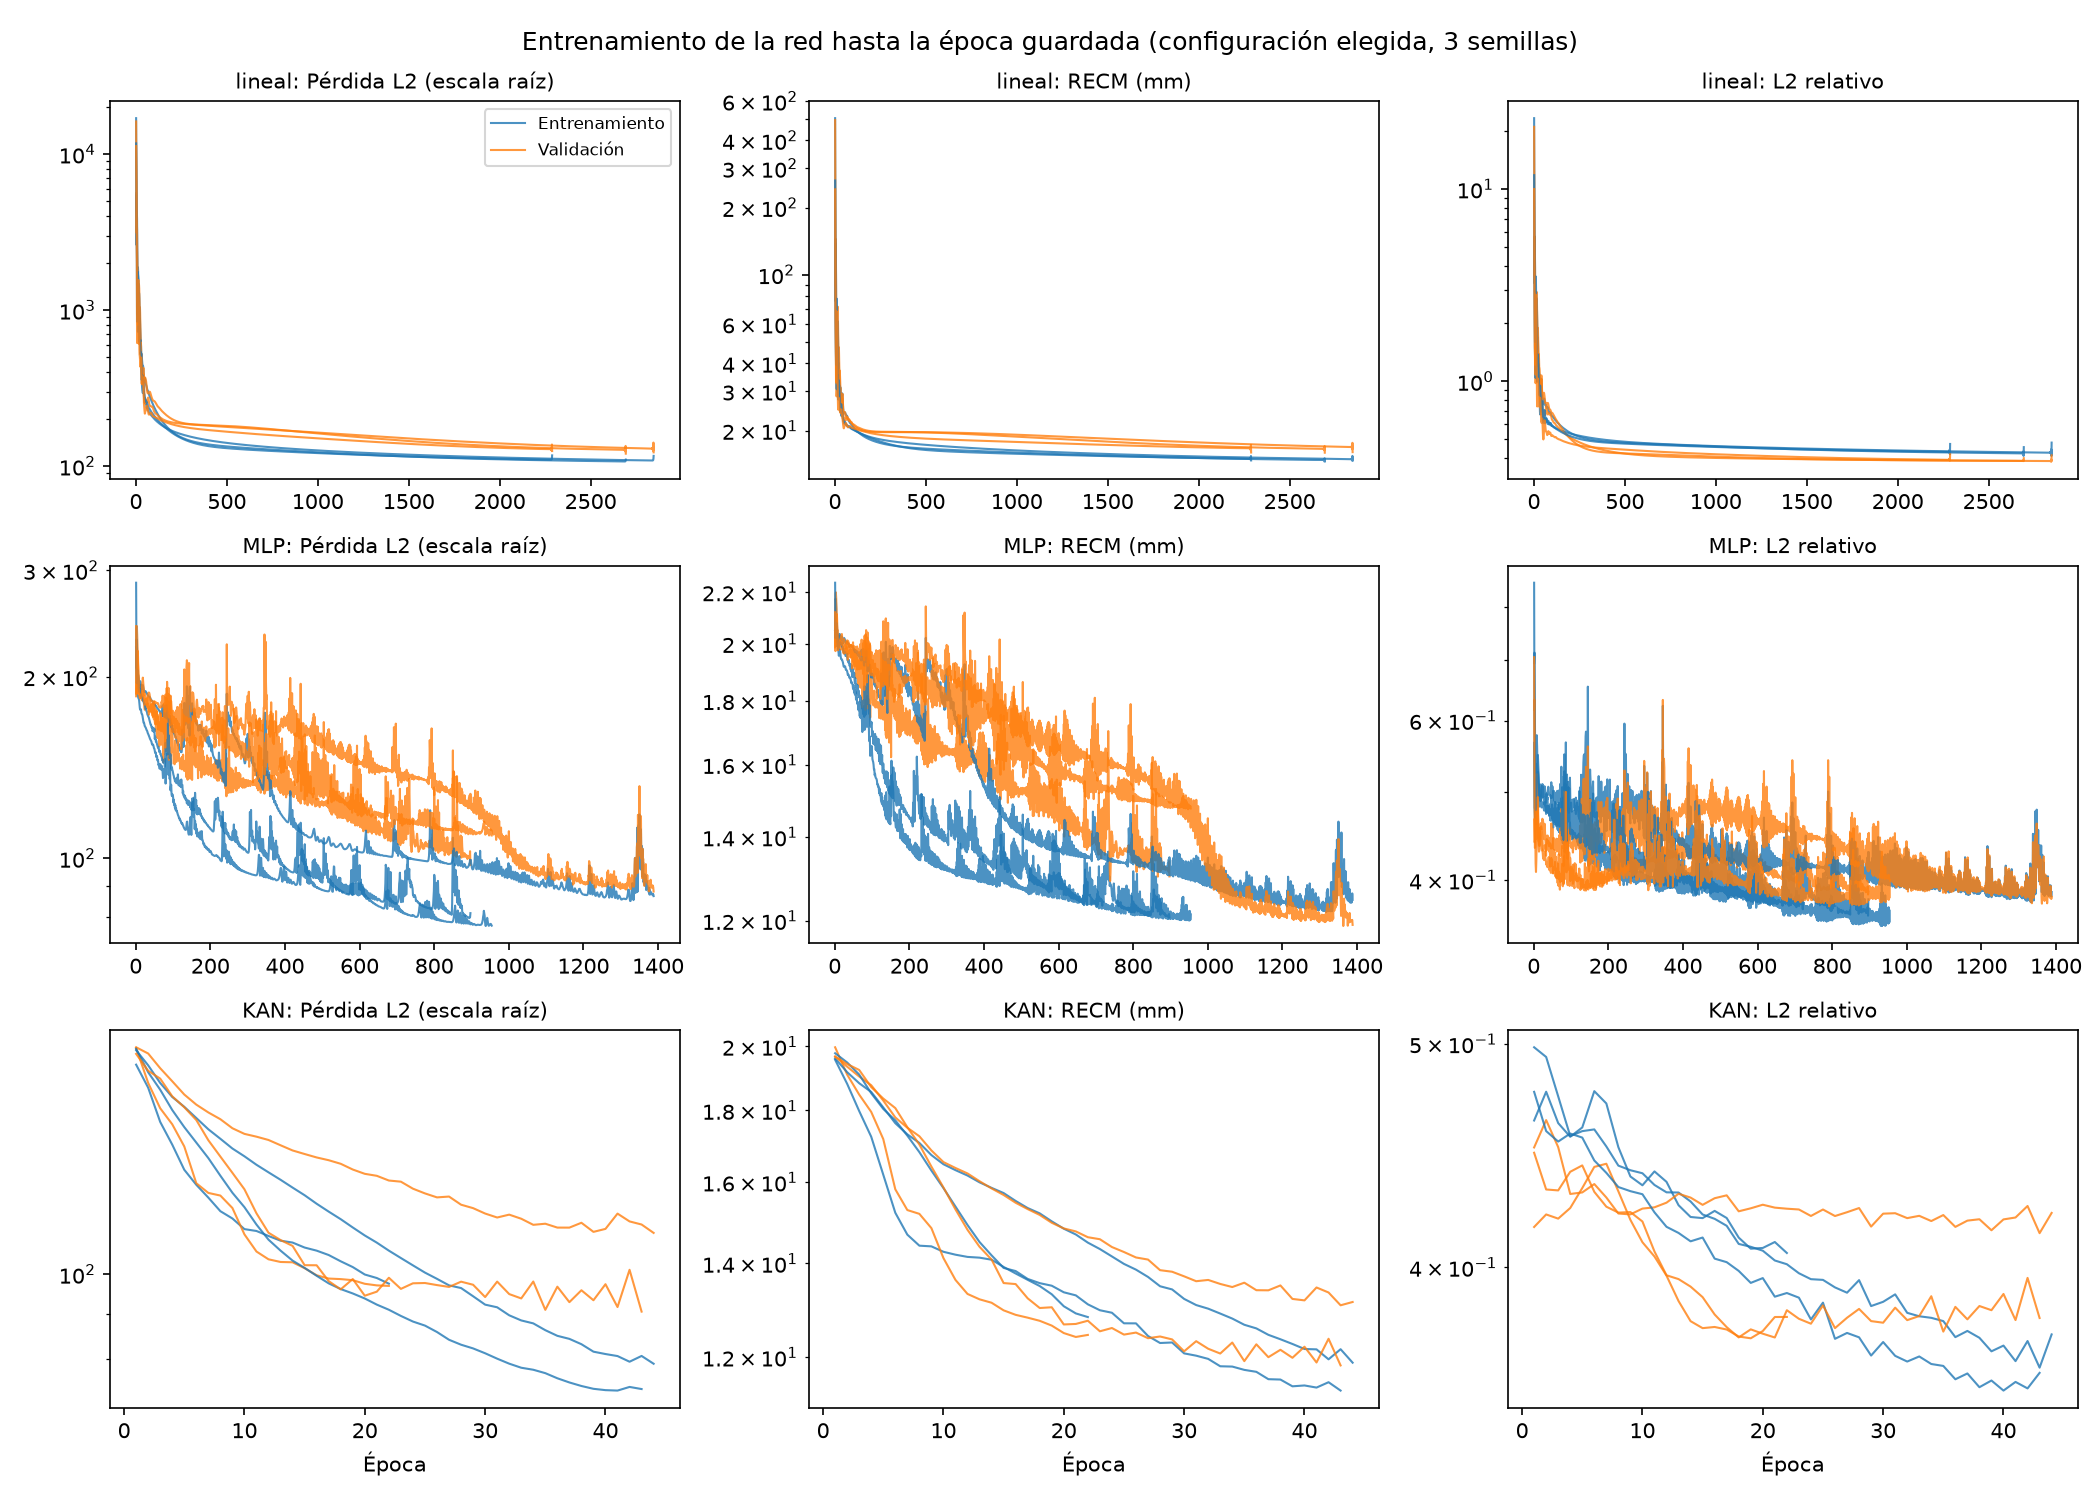

In [15]:
historial = historial_entrenamiento(ESCALA)
grafica_historial(historial, 'Figuras/08_red_curvas_entrenamiento.png')
display(Image('Figuras/08_red_curvas_entrenamiento.png', width=1000))

In [16]:
# Valores en la época guardada (media de las 3 semillas)
guardada = historial[historial.epoca == historial.mejor_epoca]
guardada.groupby('cabeza')[['mejor_epoca', 'L2_entrenamiento', 'L2_validacion', 'RECM_entrenamiento', 'RECM_validacion',
                            'L2_relativo_entrenamiento', 'L2_relativo_validacion']].mean().round(3)

,mejor_epoca,L2_entrenamiento,L2_validacion,RECM_entrenamiento,RECM_validacion,L2_relativo_entrenamiento,L2_relativo_validacion
cabeza,,,,,,,
KAN,36.333,83.546,99.692,12.024,12.476,0.380,0.394
MLP,1079.667,81.664,98.220,12.227,13.228,0.376,0.385
lineal,2609.000,114.394,122.412,14.627,15.950,0.469,0.409
